# 2. Исследовательский анализ данных (EDA)

Второй ноутбук проекта. Здесь мы смотрим на уже очищенные данные: описательная статистика, выбросы и графики. Цель — понять, какие признаки связаны с возвратом в больницу, до того как обучать модели.

Все графики строит модуль `src/eda.py` и сохраняет в `reports/figures/`; ноутбук только вызывает функции и показывает результат.

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))   # чтобы работал импорт from src ...

import pandas as pd
from IPython.display import Image, display

from src import config, data_loader, preprocessing, eda

pd.set_option('display.max_columns', 60)

Данные готовим так же, как в ноутбуке 01: загрузка → очистка.

In [2]:
clean = preprocessing.clean(data_loader.load_raw())
config.ensure_dirs()
print('Очищенная таблица:', clean.shape)
print('Доля вернувшихся раньше 30 дней:', round(clean['readmit_30'].mean() * 100, 1), '%')

Очищенная таблица: (99340, 44)
Доля вернувшихся раньше 30 дней: 11.4 %


## 2.1. Описательная статистика числовых признаков

In [3]:
eda.describe_numeric(clean)

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,99340.0,4.38,2.97,1.0,2.0,4.0,6.0,14.0
num_lab_procedures,99340.0,42.91,19.61,1.0,31.0,44.0,57.0,132.0
num_procedures,99340.0,1.33,1.70,0.0,0.0,1.0,2.0,6.0
num_medications,99340.0,15.98,8.09,1.0,10.0,15.0,20.0,81.0
number_outpatient,99340.0,0.37,1.27,0.0,0.0,0.0,0.0,42.0
number_emergency,99340.0,0.20,0.94,0.0,0.0,0.0,0.0,76.0
number_inpatient,99340.0,0.63,1.26,0.0,0.0,0.0,1.0,21.0
number_diagnoses,99340.0,7.40,1.94,1.0,6.0,8.0,9.0,16.0
total_prior_visits,99340.0,1.20,2.29,0.0,0.0,0.0,2.0,80.0
age_num,99340.0,65.74,15.95,5.0,55.0,65.0,75.0,95.0


Средний пациент — 66 лет, лежит в больнице около 4 дней, получает 16 лекарств и имеет 7–8 диагнозов. Счётчики прошлых обращений (`number_outpatient`, `number_emergency`, `number_inpatient`) сильно скошены: медиана равна 0, а максимум доходит до десятков.

## 2.2. Выбросы по правилу IQR

Выбросом считаем значение за пределами `Q1 − 1.5·IQR` и `Q3 + 1.5·IQR`.

In [4]:
eda.iqr_outliers(clean)

,feature,q1,q3,lower_bound,upper_bound,outliers,outliers_pct
0,time_in_hospital,2.0,6.0,-4.0,12.0,2147,2.16
1,num_lab_procedures,31.0,57.0,-8.0,96.0,120,0.12
2,num_procedures,0.0,2.0,-3.0,5.0,4801,4.83
3,num_medications,10.0,20.0,-5.0,35.0,2455,2.47
4,number_outpatient,0.0,0.0,0.0,0.0,16349,16.46
5,number_emergency,0.0,0.0,0.0,0.0,11094,11.17
6,number_inpatient,0.0,1.0,-1.5,2.5,6814,6.86
7,number_diagnoses,6.0,9.0,1.5,13.5,277,0.28
8,total_prior_visits,0.0,2.0,-3.0,5.0,4324,4.35
9,age_num,55.0,75.0,25.0,105.0,850,0.86


У `number_outpatient` и `number_emergency` границы равны нулю: больше 75% пациентов не имели таких визитов, поэтому формально «выбросом» становится любой, кто пришёл хотя бы раз.

**Выбросы мы считаем, но не удаляем.** Десять госпитализаций за год — это не ошибка ввода, а редкий, но настоящий пациент. Как видно ниже, именно такие пациенты возвращаются чаще всего, то есть удалив их, мы выбросили бы самую полезную часть данных.

## 2.3. Графики

### График 1. Распределение целевой переменной

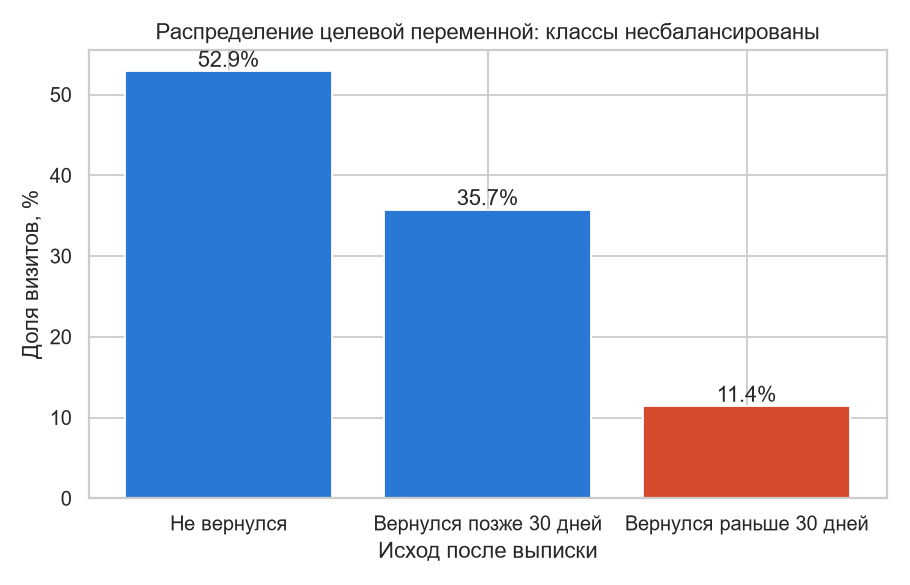

In [5]:
display(Image(filename=eda.plot_target(clean)))

**Вывод.** Раньше 30 дней возвращаются только 11.4% — классы несбалансированы. Поэтому доля правильных ответов (accuracy) здесь бесполезна: модель, которая всем отвечает «не вернётся», была бы права в 89% случаев и не нашла бы ни одного пациента.

### График 2. Возвраты и число прошлых госпитализаций

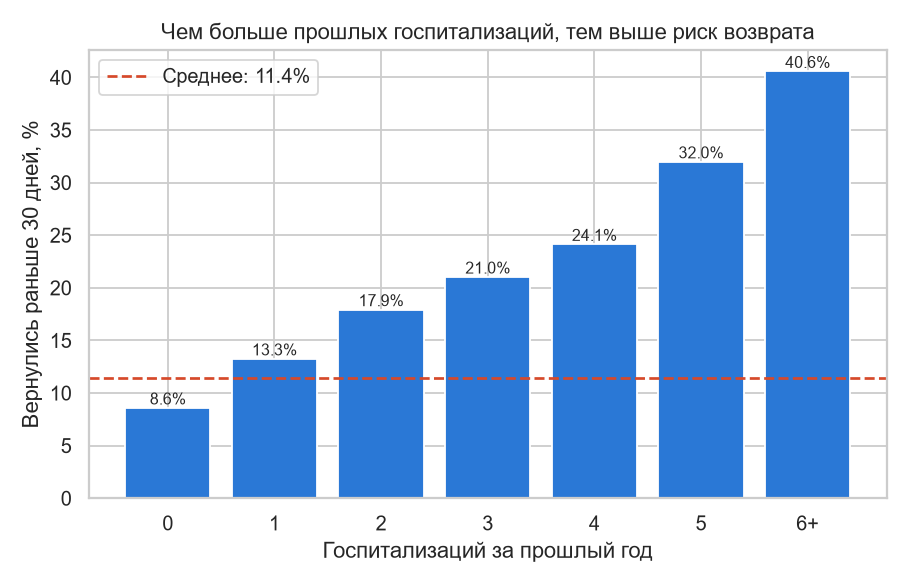

In [6]:
display(Image(filename=eda.plot_rate_by_inpatient(clean)))

**Вывод.** Самая сильная зависимость в данных: без госпитализаций за прошлый год возвращаются 8.6%, а при шести и более — 40.6%, почти в пять раз чаще.

### График 3. Возвраты по группе основного диагноза

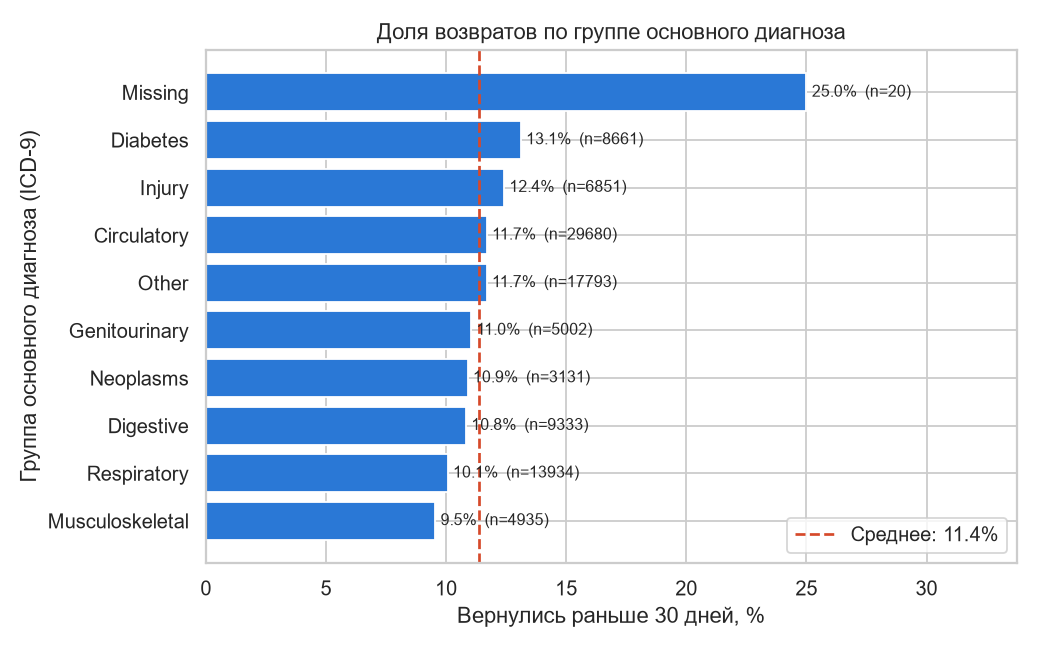

In [7]:
display(Image(filename=eda.plot_rate_by_diagnosis(clean)))

**Вывод.** Между группами диагнозов разница небольшая: от 9.5% (костно-мышечные) до 13.1% (диабет как основной диагноз). Группа `Missing` выглядит высокой, но в ней очень мало визитов, поэтому её процент ненадёжен. Диагноз сам по себе слабее предсказывает возврат, чем история госпитализаций.

### График 4. Числовые признаки у вернувшихся и не вернувшихся

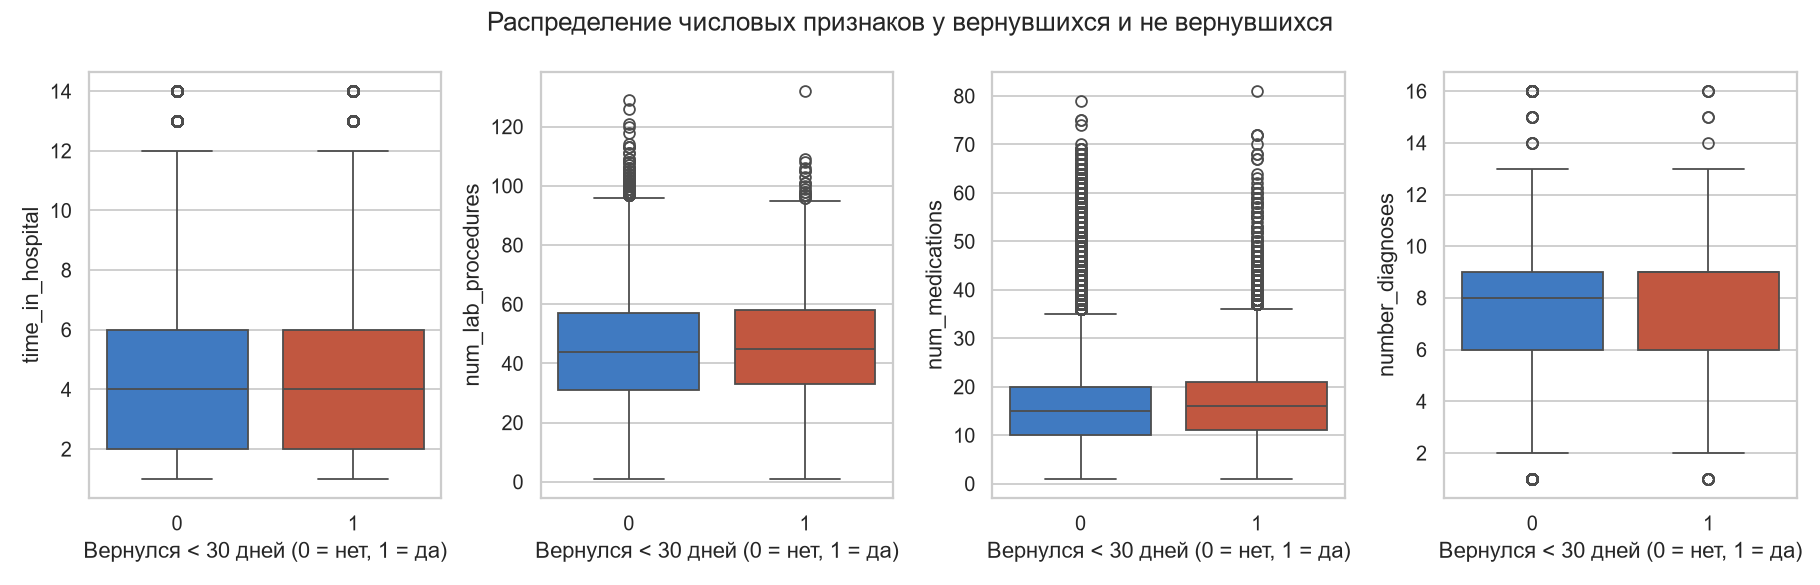

In [8]:
display(Image(filename=eda.plot_boxplots(clean)))

**Вывод.** Распределения почти совпадают. У вернувшихся чуть больше лекарств и диагнозов, но по одному такому признаку отличить группы нельзя. Значит, высокой точности от моделей ждать не стоит — это свойство самих данных.

### График 5. Корреляция

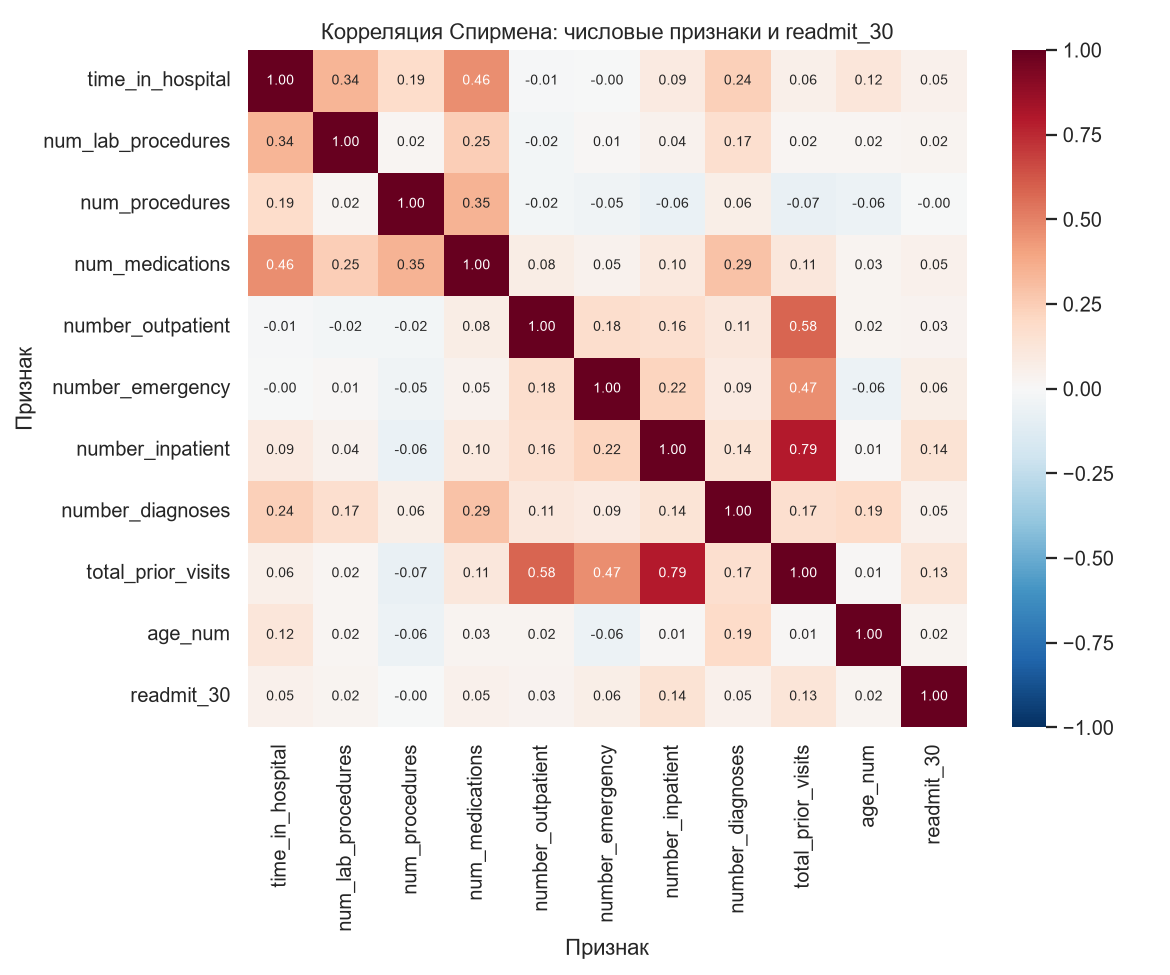

In [9]:
display(Image(filename=eda.plot_correlation(clean)))

In [10]:
numeric, _ = preprocessing.get_feature_lists(clean)
corr = clean[numeric + ['readmit_30']].corr(method='spearman')['readmit_30'].drop('readmit_30')
corr.sort_values(ascending=False).round(3).to_frame('корреляция с readmit_30')

,корреляция с readmit_30
number_inpatient,0.141
total_prior_visits,0.126
number_emergency,0.064
time_in_hospital,0.053
number_diagnoses,0.052
num_medications,0.048
number_outpatient,0.035
age_num,0.024
num_lab_procedures,0.024
num_procedures,-0.005


Используем корреляцию Спирмена, а не Пирсона: счётчики визитов сильно скошены, а Спирмен работает с рангами и не чувствителен к выбросам.

**Вывод.** Все связи с ответом слабые. Сильнее всего — `number_inpatient` (0.14) и `total_prior_visits` (0.13), у остальных признаков меньше 0.07. Между собой заметно связаны `num_medications` и `time_in_hospital`, а `total_prior_visits` — с тремя счётчиками, из которых он составлен.

### График 6. Сколько визитов у одного пациента

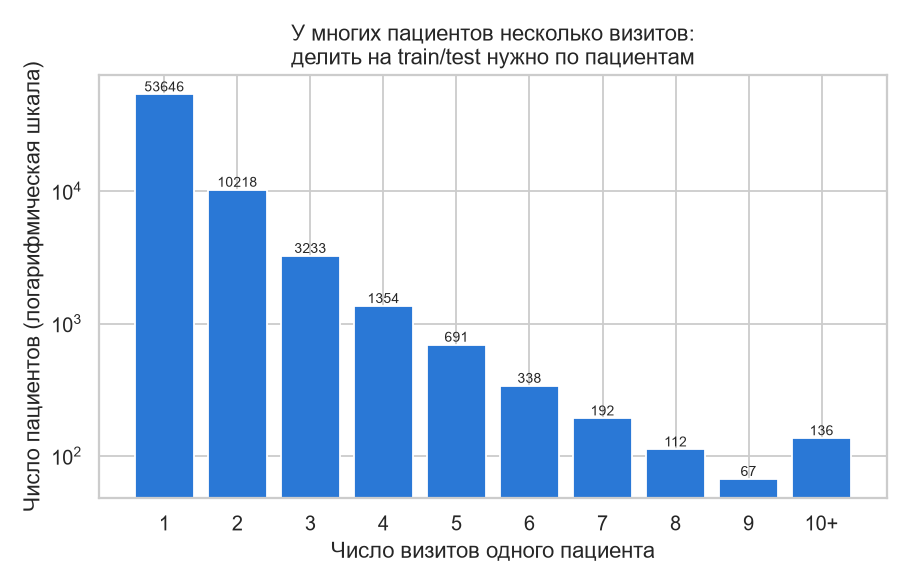

In [11]:
display(Image(filename=eda.plot_visits_per_patient(clean)))

In [12]:
visits = clean['patient_nbr'].value_counts()
print('Пациентов:', len(visits))
print('С несколькими визитами:', int((visits > 1).sum()), f'({(visits > 1).mean() * 100:.1f}%)')
print('Максимум визитов у одного пациента:', int(visits.max()))

Пациентов: 69987
С несколькими визитами: 16341 (23.3%)
Максимум визитов у одного пациента: 40


**Вывод.** Почти у четверти пациентов больше одного визита, у некоторых — десятки. Если делить данные на train и test случайно по строкам, один и тот же человек попадёт в обе части, и оценка модели будет нечестной. Поэтому в ноутбуке 03 разбиение делается по `patient_nbr`.

### График 7. Интерактивный: возраст и группа диагноза

Седьмой график сделан в Plotly и сохраняется в HTML-файл — его можно открыть в браузере, наводить мышь на точки и отключать линии. Ниже та же зависимость по возрасту в виде таблицы.

In [13]:
path = eda.plot_interactive(clean)
print('Интерактивный график сохранён:', Path(path).relative_to(config.ROOT))

by_age = clean.groupby('age', observed=True)['readmit_30'].agg(['mean', 'count'])
by_age['mean'] = (by_age['mean'] * 100).round(1)
by_age.columns = ['вернулись < 30 дней, %', 'визитов']
by_age

Интерактивный график сохранён: reports\figures\07_interactive_age_diagnosis.html


,"вернулись < 30 дней, %",визитов
age,,
[0-10),1.9,160
[10-20),5.8,690
[20-30),14.3,1649
[30-40),11.3,3764
[40-50),10.7,9607
[50-60),9.8,17060
[60-70),11.3,22058
[70-80),12.1,25329
[80-90),12.6,16434


**Вывод.** У взрослых пациентов доля возвратов почти не зависит от возраста: от 9.8% до 12.6%, с небольшим ростом к 80–90 годам. В группе 20–30 лет она выше (14.3%), но визитов там мало — 1 649 из 99 340, поэтому эта оценка менее надёжна. Детей и подростков в данных совсем мало. Возраст — слабый признак.

## Выводы

1. **Классы несбалансированы:** возвратов раньше 30 дней только 11.4%. Нужны метрики, устойчивые к дисбалансу (PR-AUC, recall), и учёт дисбаланса при обучении.
2. **Главный признак — история госпитализаций:** доля возвратов растёт с 8.6% до 40.6% вместе с числом госпитализаций за прошлый год.
3. **Остальные признаки связаны с ответом слабо:** корреляции ниже 0.07, распределения у двух групп почти совпадают. Высокого качества модели ждать не стоит.
4. **Выбросы — настоящие пациенты высокого риска,** поэтому мы их не удаляем.
5. **У 23% пациентов несколько визитов,** поэтому делить данные на train и test нужно по пациентам.